[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HernanBustamanteG/lapis26-p3-corrientes/blob/main/notebooks/08_figuras_finales.ipynb)

# 08 · Figuras finales: académicas y de prensa

Las figuras académicas (fondo blanco, PNG + PDF) resumen los resultados para la presentación; las de prensa
(fondo negro, 4K, sin jerga) cuentan lo mismo para todo público. Todas salen de los mismos datos y llevan su
procedencia en los metadatos del PNG.

In [1]:
# Celda 1: entorno. En Colab clona el repositorio, instala versiones fijas y monta Google Drive (las salidas
# quedan en MyDrive/lapis26_p3/salidas). Si numpy cambia de version, la sesion se reinicia UNA vez:
# vuelve a ejecutar esta celda. En una maquina propia solo comprueba versiones.
import os, sys, subprocess
REPO_URL = "https://github.com/HernanBustamanteG/lapis26-p3-corrientes.git"
USAR_DRIVE = True
if "google.colab" in sys.modules:
    RAIZ = "/content/lapis26-p3-corrientes"
    if not os.path.isdir(RAIZ):
        subprocess.run(["git", "clone", "-q", REPO_URL, RAIZ], check=True)
else:
    RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, RAIZ)
os.chdir(RAIZ)
from p3streams import entorno
if entorno.en_colab():
    entorno.preparar_colab(RAIZ, montar_drive=USAR_DRIVE)
entorno.resumen();

Python 3.13.16
  numpy       2.2.6
  scipy       1.18.1
  astropy     8.0.2
  gala        1.12.0


  matplotlib  3.11.2
  pandas      3.1.0


  healpy      1.20.1
  galstreams  1.2.1
Salidas en: salidas
ffmpeg: /usr/bin/ffmpeg | CPU: 2
Entorno OK


In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
import matplotlib.pyplot as plt
from p3streams import config as C, util as U, estilo as E
E.usar()
SAL = U.carpeta_nueva("08_figuras")          # carpeta nueva de este notebook (nada se pisa)
FUENTE = "notebooks/08_figuras.ipynb, p3streams " + C.VERSION + ", " + U.ahora()
print("Salidas de este notebook:", SAL)

Salidas de este notebook: salidas/08_figuras_20261027_211227


In [3]:
from p3streams import resultados as R, analisis as An, metricas as Me, figuras as F, potenciales as P
PROPIOS = False          # True: usar la corrida propia mas reciente (salidas/) en vez de la incluida en resultados/
DF, ORIGEN = R.cargar("catalogo_principal", propios=PROPIOS)
print("Catalogo: %d corrientes, leido de %s" % (len(DF), ORIGEN))
sis = P.integrar_sistema()          # el mismo sistema MW + LMC (1.8e11 Msun) del catalogo
DF = An.agregar_geometria(DF, sis)
from p3streams import prensa as Pr, corrientes as Co, catalogo as Ca
RAD, _ = R.cargar("por_radio_principal")
MAS = pd.concat([R.cargar("catalogo_masa_" + m)[0].assign(M_LMC=float(m)) for m in ("1.0", "1.5", "1.8", "2.5")])

Catalogo: 288 corrientes, leido de resultados/catalogo_principal.csv


### Figura académica de resumen

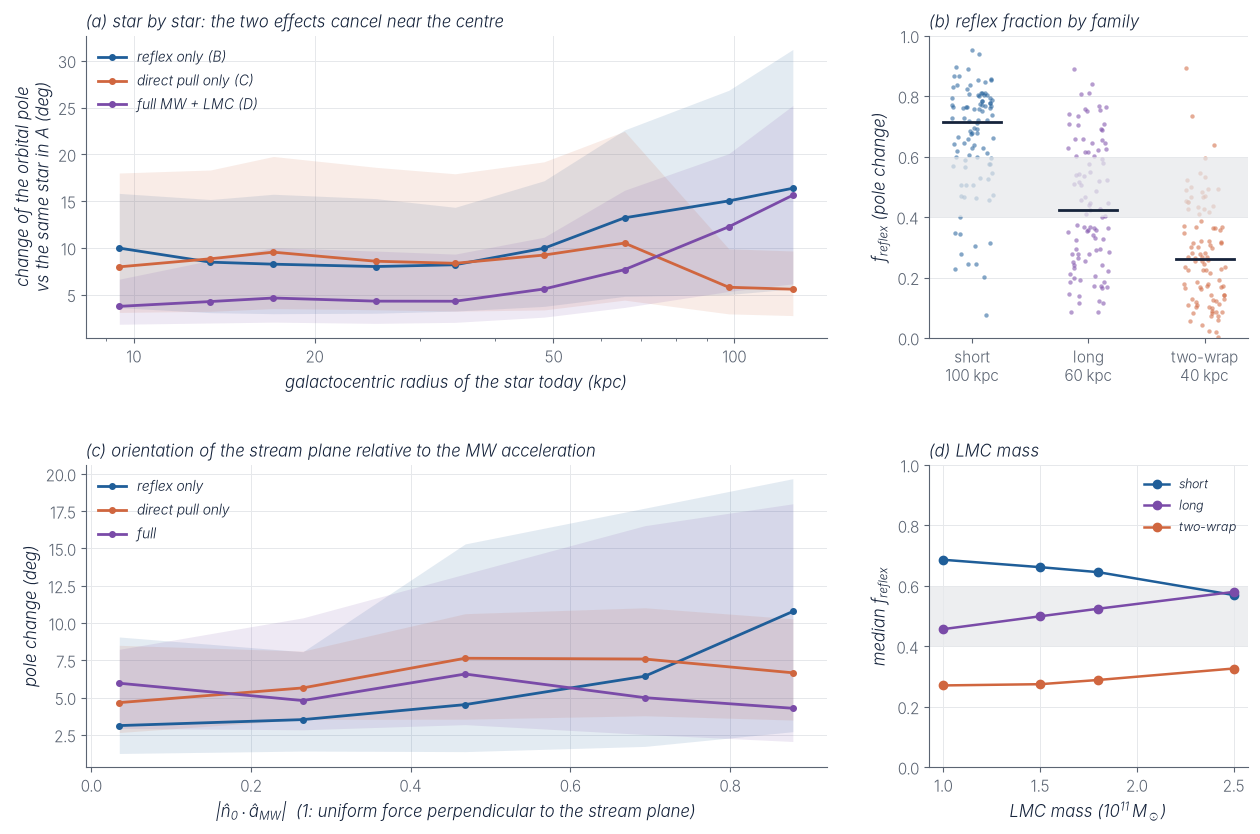

Figura: final_resumen_academico.png 
Summary. (a) Change of each star's orbital pole relative to the same star in the isolated MW, against its radius today (all streams of the main catalogue; medians and 16-84 per cent ranges): the reflex motion alone (B) and the direct pull alone (C) each tilt orbits by ~10 deg at all radii, but together (D) they largely cancel in the inner halo. (b) Reflex fraction of the mean pole change per stream family (lines: medians; grey band: mixed). (c) Pole change against the orientation of the stream plane relative to the mean MW acceleration over the last Gyr. (d) Median reflex fraction against LMC mass (12 poles x 3 families per mass).


In [4]:
fig = plt.figure(figsize=(15, 9.5))
gs = fig.add_gridspec(2, 3, hspace=0.42, wspace=0.32)
ax = fig.add_subplot(gs[0, :2])
for m, nom in (("B", "reflex only (B)"), ("C", "direct pull only (C)"), ("D", "full MW + LMC (D)")):
    ax.fill_between(RAD["r_med"], RAD["p16_" + m], RAD["p84_" + m], color=E.COLOR_MODELO[m], alpha=0.12, lw=0)
    ax.plot(RAD["r_med"], RAD["med_" + m], "-o", ms=4, lw=2, color=E.COLOR_MODELO[m], label=nom)
ax.set_xscale("log"); ax.set_xlabel("galactocentric radius of the star today (kpc)")
ax.set_ylabel("change of the orbital pole\nvs the same star in A (deg)"); ax.legend(fontsize=10, loc="upper left"); E.grilla(ax)
ax.set_title("(a) star by star: the two effects cancel near the centre", loc="left", fontsize=12)
ax = fig.add_subplot(gs[0, 2])
for i, fam in enumerate(("corta", "larga", "doble")):
    v = DF.loc[DF["familia"] == fam, "dpolo_f_reflex_todo"].to_numpy(float)
    x = i + np.random.default_rng(i).uniform(-0.18, 0.18, len(v))
    ax.scatter(x, v, s=10, color=F.COLOR_FAMILIA[fam], alpha=0.55, lw=0)
    ax.plot([i - 0.25, i + 0.25], [np.median(v)] * 2, color=E.TINTA, lw=2)
ax.axhspan(0.4, 0.6, color=E.GRILLA, alpha=0.7, lw=0)
ax.set_xticks([0, 1, 2], ["short\n100 kpc", "long\n60 kpc", "two-wrap\n40 kpc"])
ax.set_ylabel(r"$f_{\rm reflex}$ (pole change)"); ax.set_ylim(0, 1); E.grilla(ax, "y")
ax.set_title("(b) reflex fraction by family", loc="left", fontsize=12)
ax = fig.add_subplot(gs[1, :2])
for k, m, nom in (("dpolo_B_todo", "B", "reflex only"), ("dpolo_C_todo", "C", "direct pull only"), ("dpolo_D_todo", "D", "full")):
    x = DF["perp_aMW"].to_numpy(float); y = DF[k].to_numpy(float)
    c, med, lo, hi = An.medianas_por_tramo(x, y, np.linspace(0, 1.0001, 6))
    ax.fill_between(c, lo, hi, color=E.COLOR_MODELO[m], alpha=0.12, lw=0)
    ax.plot(c, med, "-o", ms=4, lw=2, color=E.COLOR_MODELO[m], label=nom)
ax.set_xlabel(r"$|\hat{\mathbf{n}}_0\cdot\hat{\mathbf{a}}_{\rm MW}|$  (1: uniform force perpendicular to the stream plane)")
ax.set_ylabel("pole change (deg)"); ax.legend(fontsize=10, loc="upper left"); E.grilla(ax)
ax.set_title("(c) orientation of the stream plane relative to the MW acceleration", loc="left", fontsize=12)
ax = fig.add_subplot(gs[1, 2])
for fam in ("corta", "larga", "doble"):
    g = MAS[MAS["familia"] == fam].groupby("M_LMC")["dpolo_f_reflex_todo"].median()
    ax.plot(g.index, g.values, "-o", color=F.COLOR_FAMILIA[fam], label=F.NOMBRE_FAMILIA[fam])
ax.axhspan(0.4, 0.6, color=E.GRILLA, alpha=0.7, lw=0)
ax.set_xlabel(r"LMC mass ($10^{11}\,M_\odot$)"); ax.set_ylabel(r"median $f_{\rm reflex}$"); ax.set_ylim(0, 1)
ax.legend(fontsize=9); E.grilla(ax)
ax.set_title("(d) LMC mass", loc="left", fontsize=12)
PIE = "Summary. (a) Change of each star's orbital pole relative to the same star in the isolated MW, against its radius today (all streams of the main catalogue; medians and 16-84 per cent ranges): the reflex motion alone (B) and the direct pull alone (C) each tilt orbits by ~10 deg at all radii, but together (D) they largely cancel in the inner halo. (b) Reflex fraction of the mean pole change per stream family (lines: medians; grey band: mixed). (c) Pole change against the orientation of the stream plane relative to the mean MW acceleration over the last Gyr. (d) Median reflex fraction against LMC mass (12 poles x 3 families per mass)."
E.guardar(fig, os.path.join(SAL, 'final_resumen_academico.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'final_resumen_academico.png', "\n" + PIE)

### Figuras de prensa (4K, fondo negro)

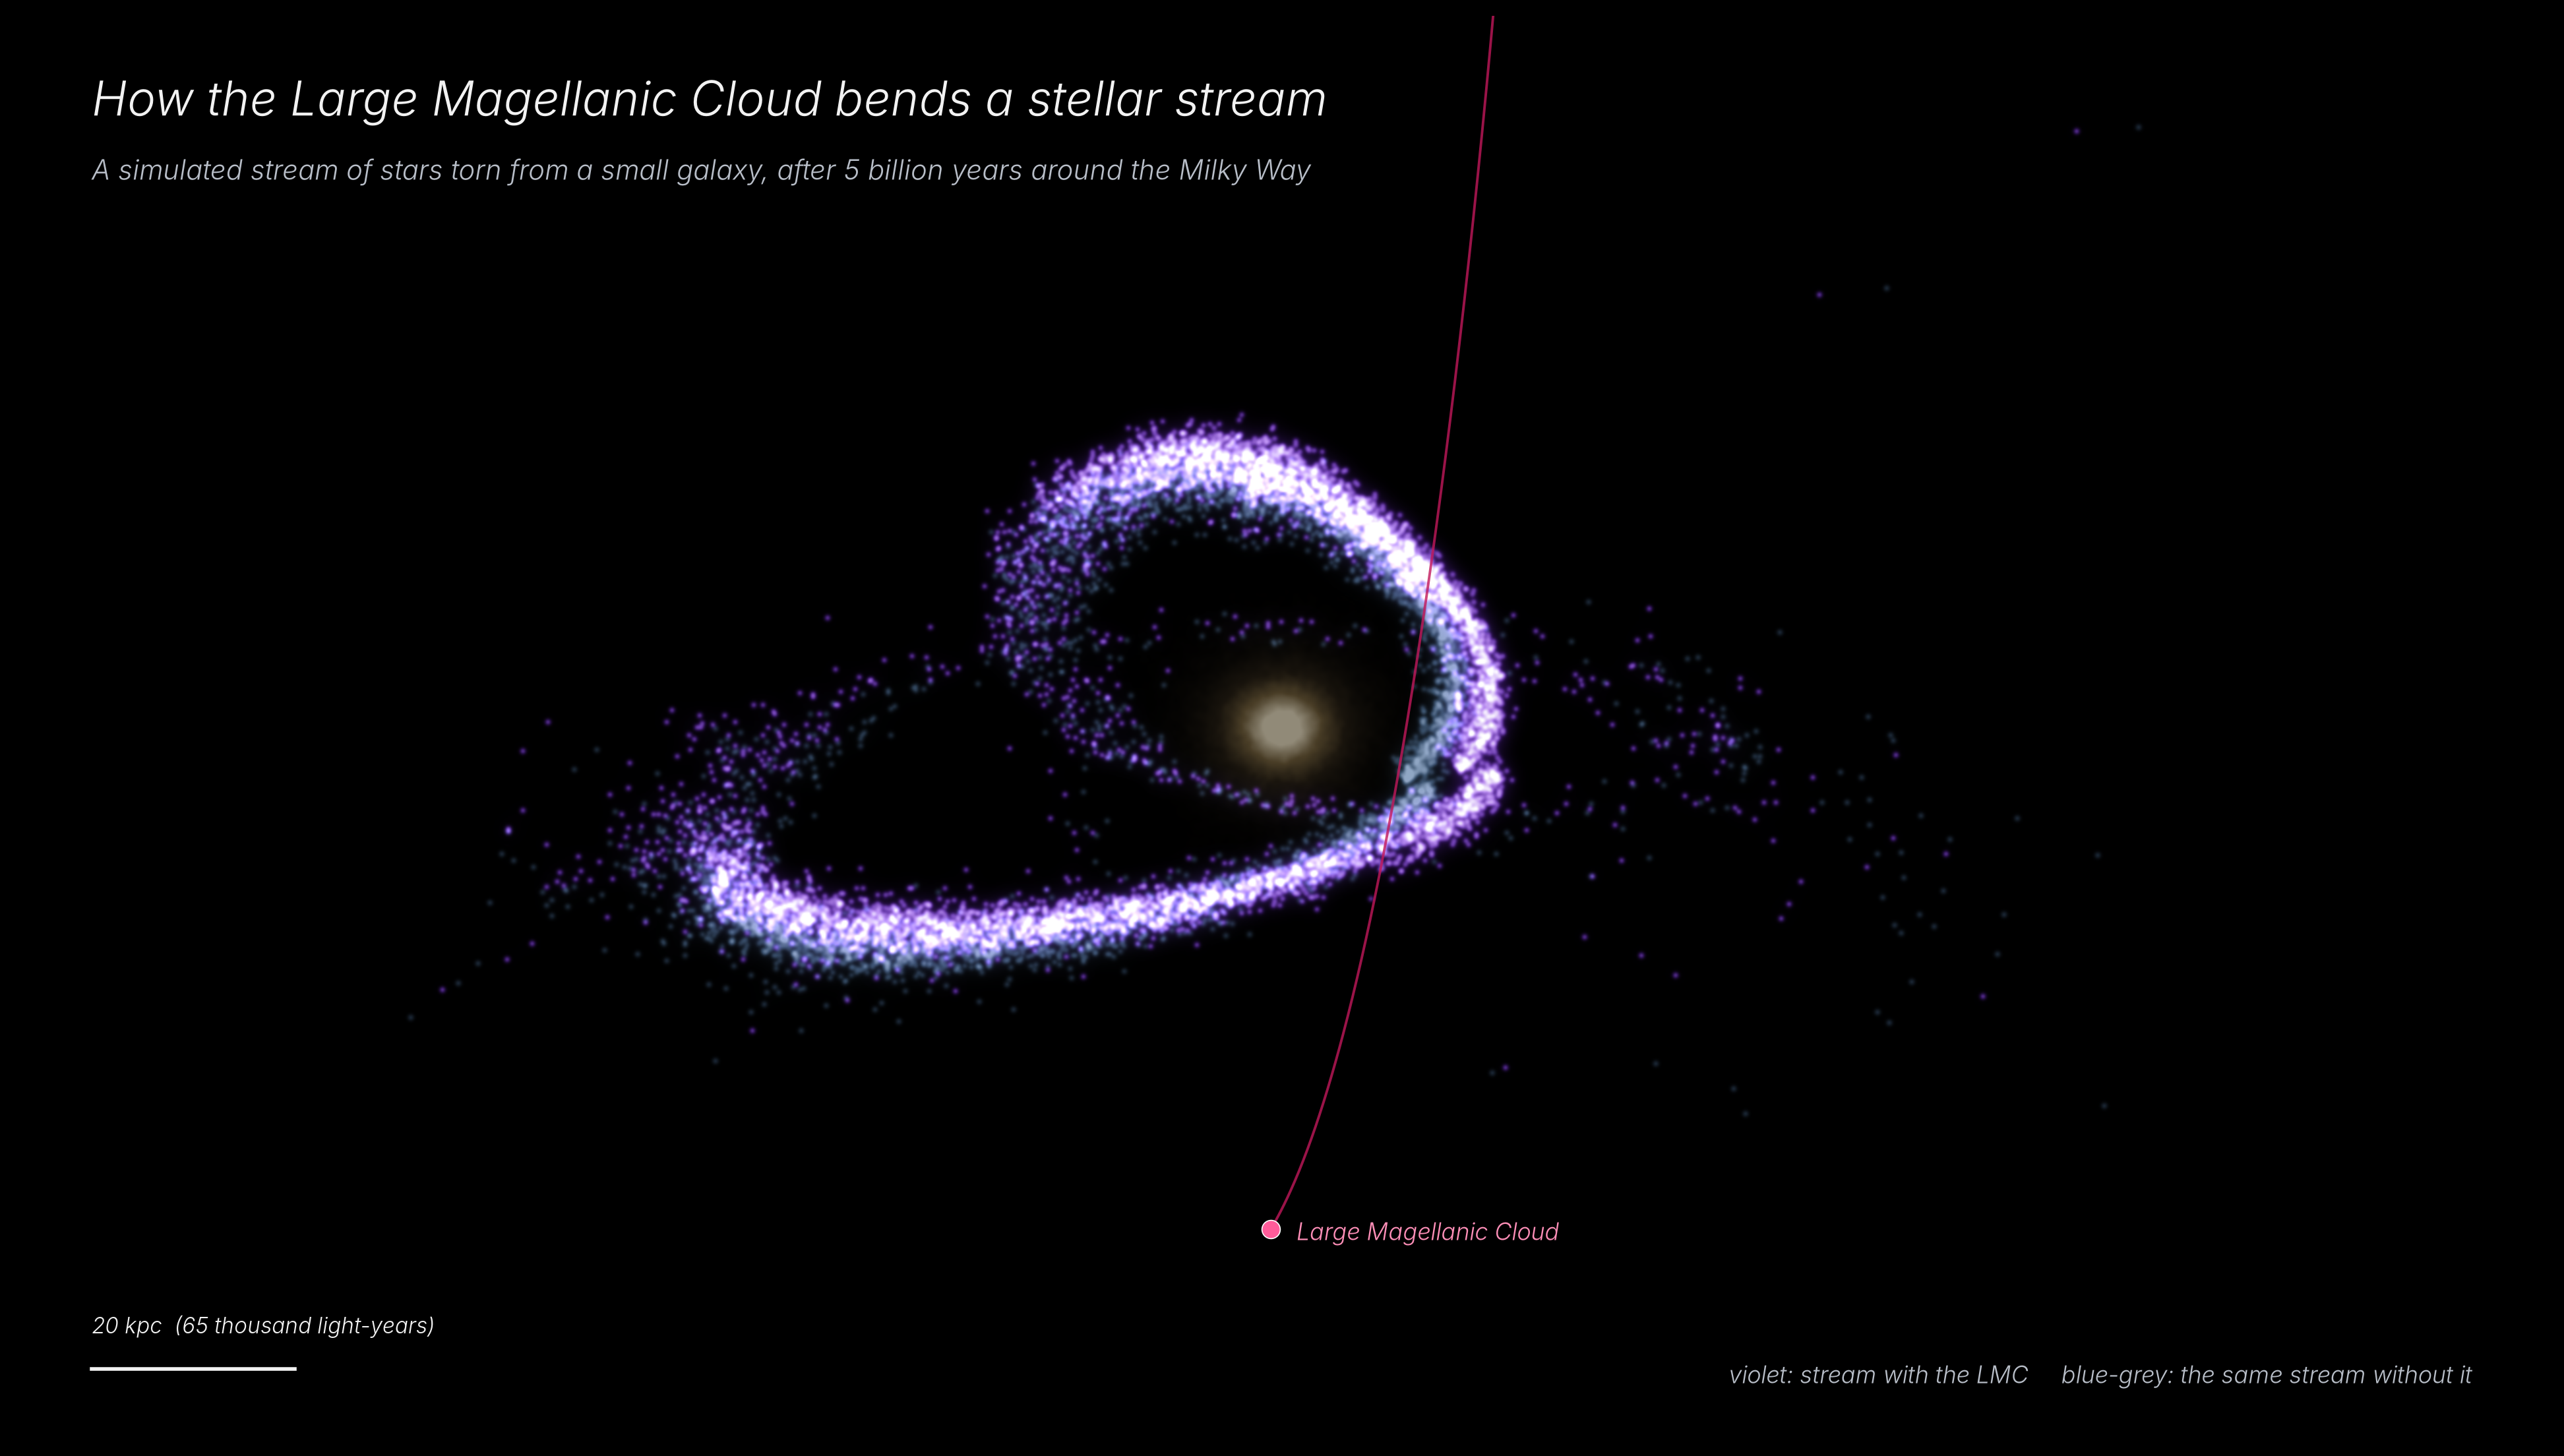

In [5]:
fam = Ca.FAMILIAS["larga"]; N0 = np.array([0.0, -1.0, 0.0])
x0, v0 = Co.condiciones_iniciales(N0, fam["r_apo"], 0.5, 0.0)
MODS = P.modelos(sis)
CORR = {m: Co.generar(MODS[m], x0, v0, m_prog=fam["m_prog"], t_inicio=-C.T_START) for m in "AD"}
fig = Pr.heroe(CORR["D"], CORR["A"], sis, N0, x0, "How the Large Magellanic Cloud bends a stellar stream",
               "A simulated stream of stars torn from a small galaxy, after 5 billion years around the Milky Way")
Pr.guardar(fig, os.path.join(SAL, "prensa_corriente_4k.png"),
           "Press image. Simulated stellar stream (5e7 Msun progenitor, apocentre 60 kpc, 5 Gyr) in the Milky Way "
           "with the Large Magellanic Cloud (violet) and the same stream in the Milky Way alone (blue-grey), seen "
           "obliquely; warm glow: exponential disc of the model; magenta: LMC orbit over the last 0.7 Gyr.", FUENTE)
plt.show()

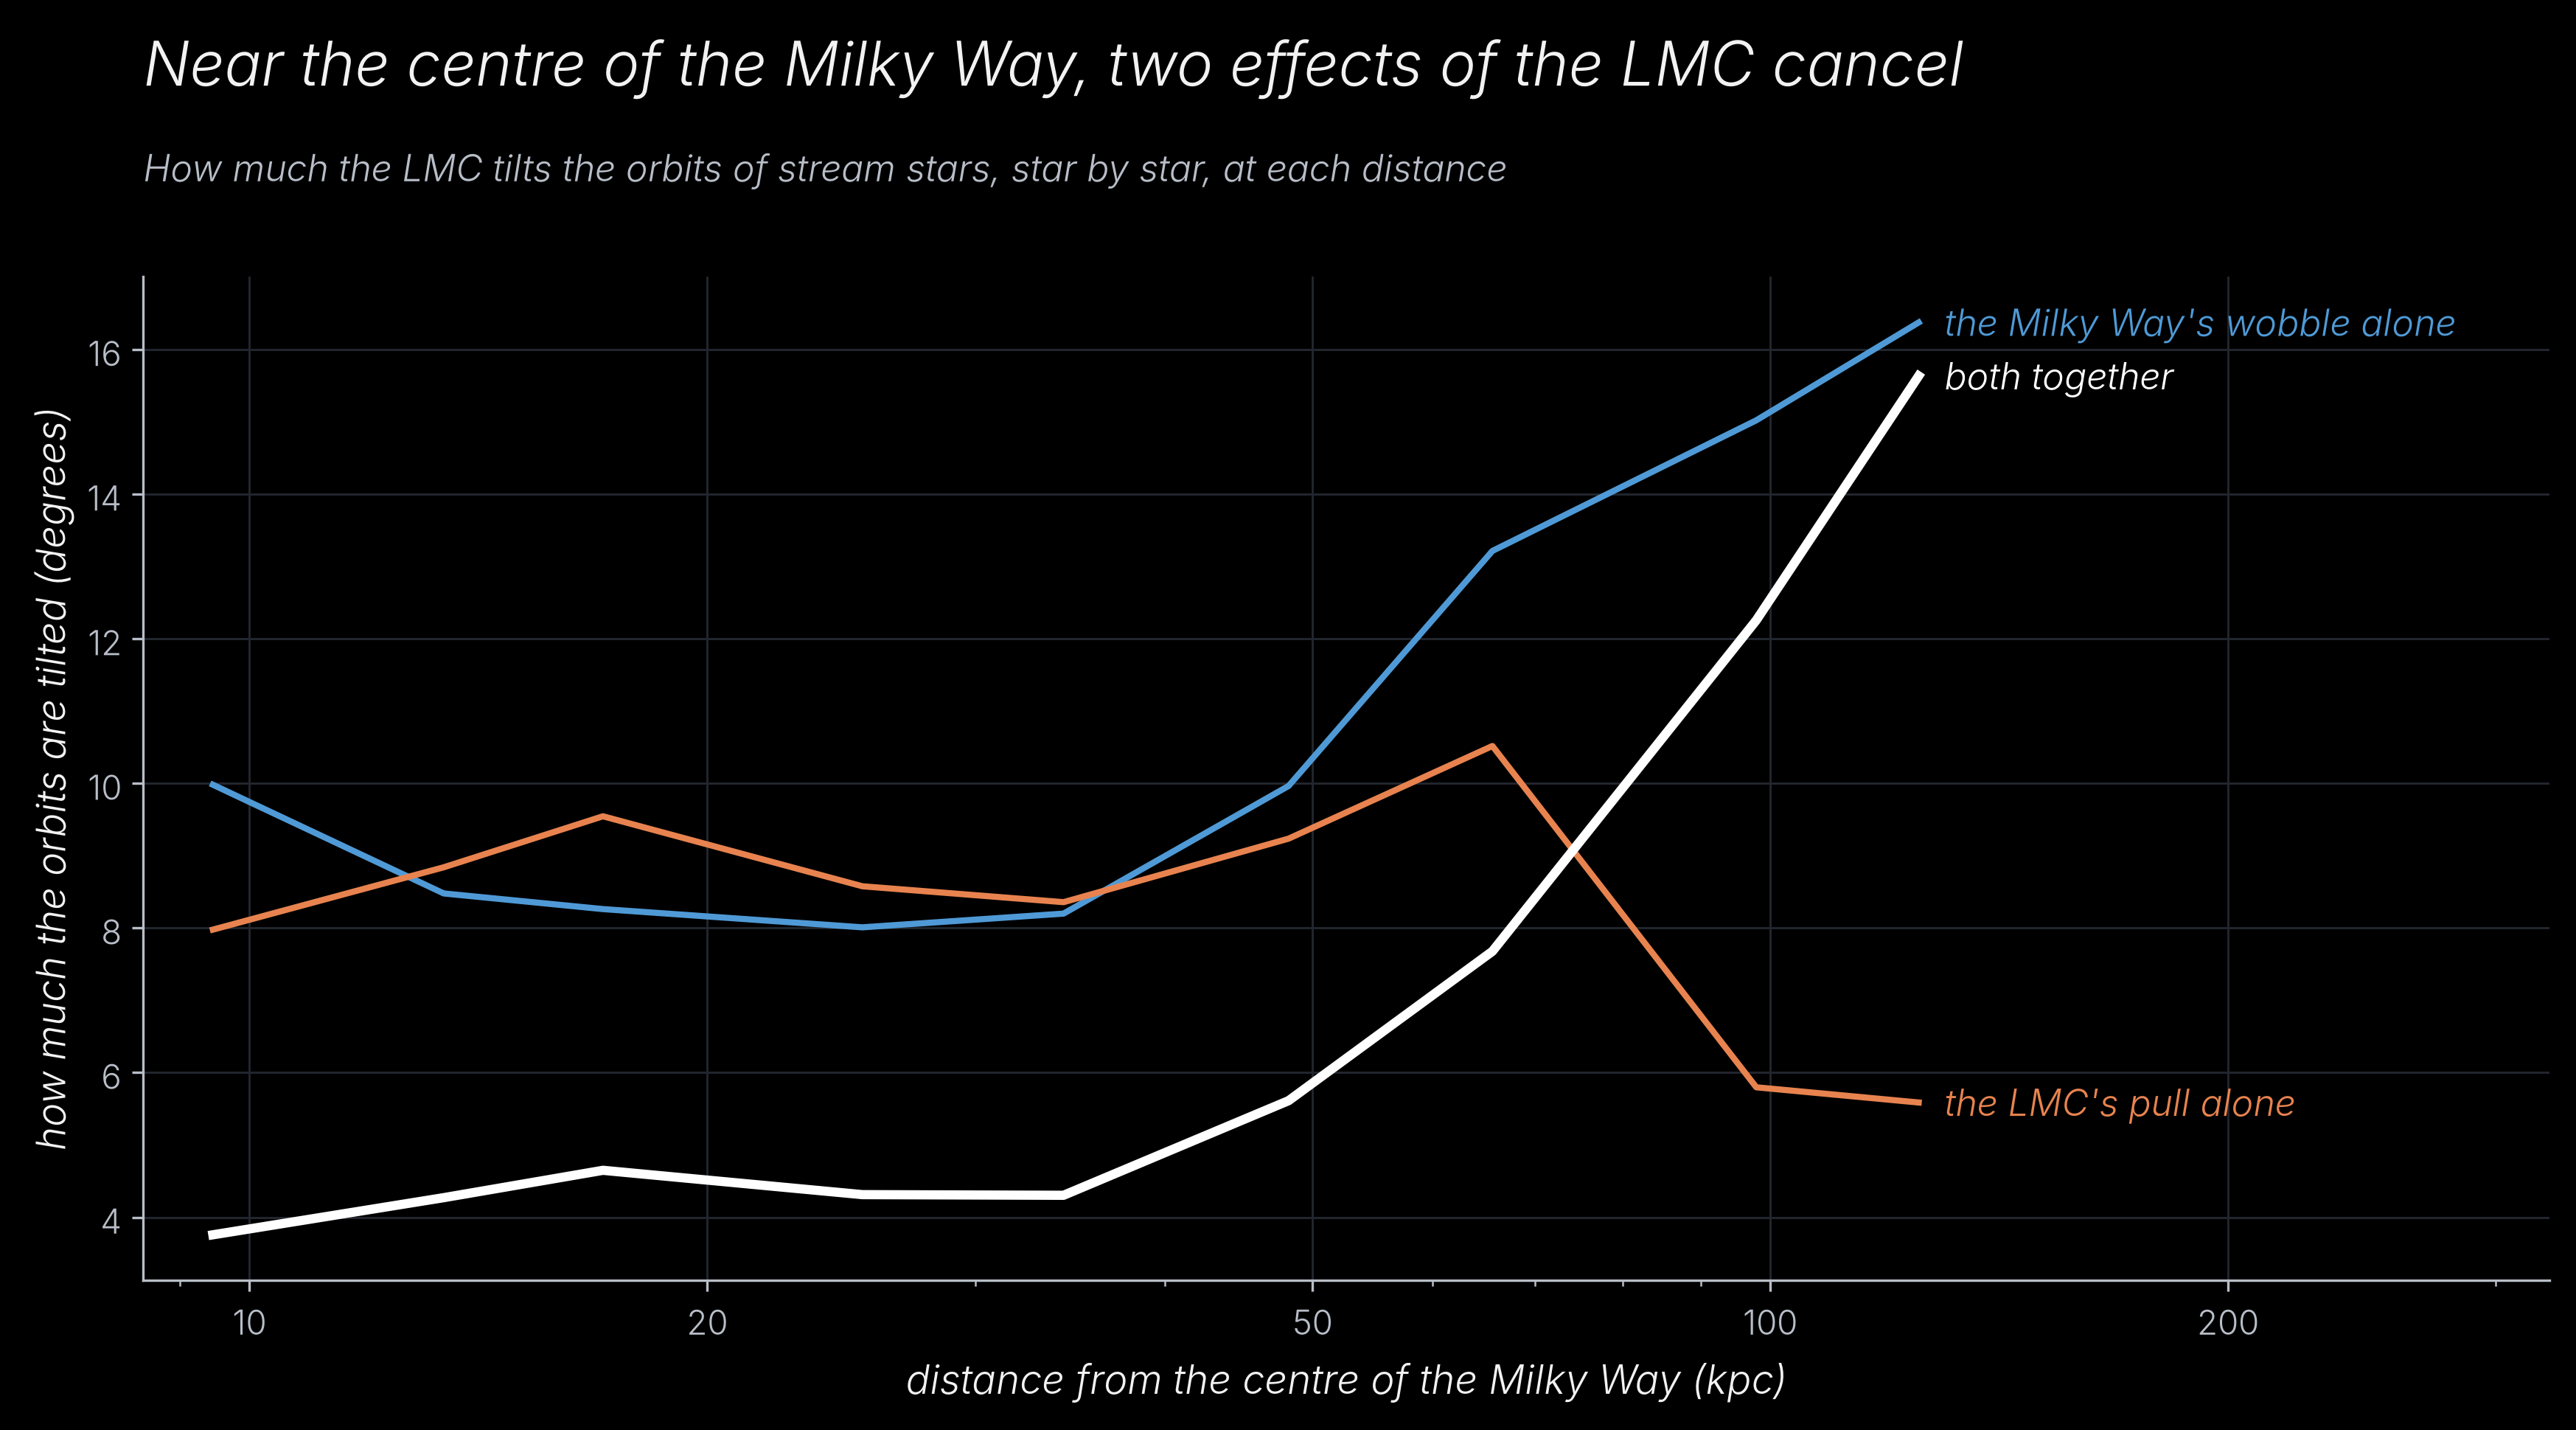

In [6]:
fig = Pr.radio(RAD, "Near the centre of the Milky Way, two effects of the LMC cancel",
               "How much the LMC tilts the orbits of stream stars, star by star, at each distance")
Pr.guardar(fig, os.path.join(SAL, "prensa_cancelacion_4k.png"),
           "Press chart. Median change of the orbital pole of stream stars caused by the LMC, against distance "
           "from the Milky Way centre: the Milky Way's own acceleration towards the LMC ('wobble', reflex motion) "
           "and the LMC's direct pull each tilt orbits, but near the centre they largely cancel.", FUENTE)
plt.show()